# TRUSTSR Lab 01.3 — Conservative Handling of Unknown Dependencies

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Status:** Synthetic simulation / research prototype  
**Version:** 0.1.0

## Objective

Compare ordinary reachability-based contamination analysis with a precisely defined conservative policy when dependency information is incomplete.

**All outputs in this notebook are synthetic simulation results.** No real agent traces, external datasets, or production systems are used.

## Three distinct state labels

- **Confirmed contaminated:** The state is explicitly identified as the poison source in this synthetic setup.
- **Potentially contaminated:** The state is reachable from the known poison source through the observed dependency graph.
- **Unknown / unverified:** The state cannot be ruled safe under the conservative policy because a declared dependency edge is missing and the policy's uncertainty boundary includes it. This is not the same as proven contamination.

For evaluation only, the unchanged ground-truth graph identifies the synthetic expected affected descendants. That ground truth is not available to the policy itself.

## Policy definitions

1. **Baseline reachability:** Flag only descendants reachable from the known poison source in the observed graph.
2. **Conservative unknown-dependency policy:** In addition to reachable descendants, mark as unknown/unverified any nodes in the ground-truth graph that are downstream of the dependent endpoint of a missing edge. This policy uses a declared missing-edge list as an uncertainty signal. In a real system, that signal would need to come from instrumentation, integrity checks, or a dependency-audit mechanism.

This policy is intentionally explicit and illustrative. It is not claimed to be optimal or generally superior. We will measure both missed affected states and the additional states marked unknown.

## Evaluation measures

- **False negatives:** Expected affected descendants in ground truth that the policy does not flag as either potentially contaminated or unknown.
- **Additional unknown states:** States newly marked unknown by the conservative policy that were not marked potentially contaminated by baseline reachability.
- **Extra unknown states not expected affected:** Unknown states outside the synthetic ground-truth affected set. These indicate conservative over-quarantine in this scenario.
- **Coverage of expected affected states:** Fraction of expected affected descendants either flagged as potentially contaminated or unknown.

The poison source itself is reported separately and is excluded from descendant metrics.

## 1. Environment setup

In [1]:
%pip -q install networkx pandas matplotlib

In [2]:
import sys
import platform
from datetime import datetime, timezone

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NetworkX:", nx.__version__)
print("Pandas:", pd.__version__)
print("Execution timestamp (UTC):", datetime.now(timezone.utc).isoformat())
print("Evidence type: synthetic simulation only")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
NetworkX: 3.6.1
Pandas: 3.0.2
Execution timestamp (UTC): 2026-10-11T10:26:25.417457+00:00
Evidence type: synthetic simulation only


## 2. Define the fixed synthetic ground-truth graph

This graph matches Labs 01–01.2. The ground-truth graph remains unchanged. Edge direction is `source → dependent state`.

In [3]:
states = [
    {"id": "M1", "label": "Trusted project requirement", "kind": "memory", "status": "trusted"},
    {"id": "M2", "label": "Poisoned memory: unsafe instruction", "kind": "memory", "status": "poisoned"},
    {"id": "D1", "label": "Planning decision A", "kind": "decision", "status": "normal"},
    {"id": "D2", "label": "Planning decision B", "kind": "decision", "status": "normal"},
    {"id": "P1", "label": "Execution plan A", "kind": "plan", "status": "normal"},
    {"id": "P2", "label": "Execution plan B", "kind": "plan", "status": "normal"},
    {"id": "A1", "label": "Derived action record", "kind": "action", "status": "normal"},
    {"id": "S1", "label": "Independent status note", "kind": "state", "status": "normal"},
]
dependencies = [
    ("M1", "D1"),
    ("M2", "D1"),
    ("D1", "P1"),
    ("P1", "A1"),
    ("M2", "D2"),
    ("D2", "P2"),
    ("M1", "S1"),
]
POISON_SOURCE = "M2"

G_truth = nx.DiGraph()
for state in states:
    G_truth.add_node(state["id"], **state)
G_truth.add_edges_from(dependencies)

expected_affected = set(nx.descendants(G_truth, POISON_SOURCE))
all_nodes = set(G_truth.nodes())

assert nx.is_directed_acyclic_graph(G_truth)
assert expected_affected == {"D1", "D2", "P1", "P2", "A1"}

print("Ground-truth nodes:", G_truth.number_of_nodes())
print("Ground-truth edges:", G_truth.number_of_edges())
print("Expected affected descendants:", sorted(expected_affected))
display(pd.DataFrame(dependencies, columns=["source", "dependent"]))

Ground-truth nodes: 8
Ground-truth edges: 7
Expected affected descendants: ['A1', 'D1', 'D2', 'P1', 'P2']


  source dependent
0     M1        D1
1     M2        D1
2     D1        P1
3     P1        A1
4     M2        D2
5     D2        P2
6     M1        S1

## 3. Define the two policies

For this experiment, a missing edge is provided to the conservative policy as an explicit uncertainty signal. The policy marks the missing edge's dependent endpoint and all of its downstream descendants in the ground-truth graph as `unknown_unverified`, unless already reachable from the poison source in the observed graph.

This deliberately models a policy that knows which edge is missing but does not know whether the dependent branch is safe. It does not infer missing edges automatically. The ground-truth graph is used only to construct controlled missing-edge scenarios and evaluate the experiment; the policy's uncertainty boundary is computed from the missing edge's endpoint in a declared node/edge inventory.

In [4]:
def baseline_reachability(observed_graph, source):
    """Flag only descendants reachable from source in the observed graph."""
    return set(nx.descendants(observed_graph, source))

def conservative_unknown_policy(observed_graph, source, missing_edges):
    """Return status sets using explicit missing-edge uncertainty signals.

    Policy:
    - source is separately confirmed contaminated;
    - observed-graph descendants are potentially contaminated;
    - for each declared missing edge (u, v), v and its downstream descendants
      in the fixed state inventory's dependency model are unknown/unverified,
      except states already marked potentially contaminated.

    In this synthetic implementation, downstream closure is calculated on the
    ground-truth graph solely to model the declared uncertainty boundary.
    That makes the policy an illustrative upper-bound-style simulation, not a
    deployable algorithm; a real system would need a trustworthy inventory of
    declared dependencies and an explicit boundary rule.
    """
    potential = baseline_reachability(observed_graph, source)
    unknown = set()

    for u, v in missing_edges:
        if v not in G_truth:
            continue
        unknown.add(v)
        unknown.update(nx.descendants(G_truth, v))

    unknown -= potential
    unknown.discard(source)
    return potential, unknown

def evaluate_scenario(missing_edges, scenario_name):
    observed = G_truth.copy()
    for edge in missing_edges:
        if not observed.has_edge(*edge):
            raise ValueError(f"Missing-edge scenario references an invalid edge: {edge}")
        observed.remove_edge(*edge)

    baseline_potential = baseline_reachability(observed, POISON_SOURCE)
    baseline_fn = expected_affected - baseline_potential

    conservative_potential, conservative_unknown = conservative_unknown_policy(
        observed, POISON_SOURCE, missing_edges
    )
    conservative_covered = conservative_potential | conservative_unknown
    conservative_fn = expected_affected - conservative_covered

    unknown_outside_truth = conservative_unknown - expected_affected
    additional_unknown = conservative_unknown - baseline_potential

    denom = len(expected_affected)
    return {
        "scenario": scenario_name,
        "removed_edges": "; ".join(f"{u}->{v}" for u, v in missing_edges) or "(none)",
        "removed_edge_count": len(missing_edges),
        "baseline_false_negatives": len(baseline_fn),
        "baseline_fnr": len(baseline_fn) / denom if denom else float("nan"),
        "conservative_false_negatives": len(conservative_fn),
        "conservative_fnr": len(conservative_fn) / denom if denom else float("nan"),
        "baseline_coverage": len(baseline_potential & expected_affected) / denom if denom else float("nan"),
        "conservative_coverage": len(conservative_covered & expected_affected) / denom if denom else float("nan"),
        "additional_unknown_count": len(additional_unknown),
        "unknown_outside_expected_affected_count": len(unknown_outside_truth),
        "baseline_fn_states": sorted(baseline_fn),
        "conservative_fn_states": sorted(conservative_fn),
        "potential_states": sorted(conservative_potential),
        "unknown_states": sorted(conservative_unknown),
        "unknown_outside_expected_affected_states": sorted(unknown_outside_truth),
    }

print("Policies defined. Baseline uses observed graph reachability.")
print("Conservative policy uses explicit missing-edge signals and marks an uncertainty boundary.")
print("No claim of superiority is assumed; metrics will be compared below.")

Policies defined. Baseline uses observed graph reachability.
Conservative policy uses explicit missing-edge signals and marks an uncertainty boundary.
No claim of superiority is assumed; metrics will be compared below.


## 4. Run the baseline scenario and selected missing-edge scenarios

The scenarios include no missing edges, one missing edge from Lab 01.1, the highest-impact single edge from Lab 01.2, and selected multi-edge failures.

In [5]:
scenarios = [
    ("Complete graph baseline", []),
    ("Missing D1 -> P1", [("D1", "P1")]),
    ("Missing M2 -> D1", [("M2", "D1")]),
    ("Missing M2 -> D1 and M2 -> D2", [("M2", "D1"), ("M2", "D2")]),
    ("Missing D1 -> P1 and P1 -> A1", [("D1", "P1"), ("P1", "A1")]),
    ("Missing M1 -> S1 (unaffected branch)", [("M1", "S1")]),
]

results = [evaluate_scenario(edges, name) for name, edges in scenarios]
results_df = pd.DataFrame(results)

display(results_df[[
    "scenario", "removed_edge_count",
    "baseline_false_negatives", "baseline_fnr",
    "conservative_false_negatives", "conservative_fnr",
    "additional_unknown_count", "unknown_outside_expected_affected_count",
    "baseline_coverage", "conservative_coverage"
]])

                               scenario  removed_edge_count  baseline_false_negatives  baseline_fnr  conservative_false_negatives  conservative_fnr  additional_unknown_count  \
0               Complete graph baseline                   0                         0           0.0                             0               0.0                         0   
1                      Missing D1 -> P1                   1                         2           0.4                             0               0.0                         2   
2                      Missing M2 -> D1                   1                         3           0.6                             0               0.0                         3   
3         Missing M2 -> D1 and M2 -> D2                   2                         5           1.0                             0               0.0                         5   
4         Missing D1 -> P1 and P1 -> A1                   2                         2           0.4                

## 5. State-level classification for each scenario

Status categories are mutually interpretable:
- `confirmed_contaminated`: the declared source `M2`;
- `potentially_contaminated`: reachable from M2 in the observed graph;
- `unknown_unverified`: inside the conservative uncertainty boundary but not already potentially contaminated;
- `not_flagged_by_either`: neither reachable nor included in the declared uncertainty boundary.

These labels are outputs of the synthetic policy, not calibrated real-world trust states.

In [6]:
def state_classification_table(missing_edges, scenario_name):
    observed = G_truth.copy()
    for edge in missing_edges:
        observed.remove_edge(*edge)

    potential, unknown = conservative_unknown_policy(observed, POISON_SOURCE, missing_edges)
    rows = []
    for node in sorted(all_nodes):
        if node == POISON_SOURCE:
            status = "confirmed_contaminated"
        elif node in potential:
            status = "potentially_contaminated"
        elif node in unknown:
            status = "unknown_unverified"
        else:
            status = "not_flagged_by_either"

        rows.append({
            "scenario": scenario_name,
            "state_id": node,
            "state_label": G_truth.nodes[node]["label"],
            "synthetic_ground_truth_affected": node in expected_affected,
            "baseline_flagged": node in potential,
            "conservative_unknown": node in unknown,
            "conservative_status": status,
        })
    return pd.DataFrame(rows)

state_tables = pd.concat(
    [state_classification_table(edges, name) for name, edges in scenarios],
    ignore_index=True
)
display(state_tables[state_tables["scenario"] == "Missing D1 -> P1"])

            scenario state_id                          state_label  synthetic_ground_truth_affected  baseline_flagged  conservative_unknown       conservative_status
8   Missing D1 -> P1       A1                Derived action record                             True             False                  True        unknown_unverified
9   Missing D1 -> P1       D1                  Planning decision A                             True              True                 False  potentially_contaminated
10  Missing D1 -> P1       D2                  Planning decision B                             True              True                 False  potentially_contaminated
11  Missing D1 -> P1       M1          Trusted project requirement                            False             False                 False     not_flagged_by_either
12  Missing D1 -> P1       M2  Poisoned memory: unsafe instruction                            False             False                 False    confirmed_contaminated
13  

## 6. Plot baseline vs conservative false-negative rates

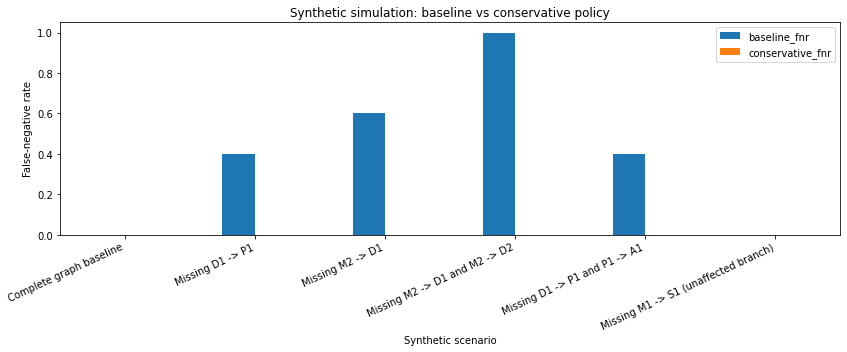

In [7]:
plot_metrics = results_df.set_index("scenario")[["baseline_fnr", "conservative_fnr"]]
ax = plot_metrics.plot(kind="bar", figsize=(12, 5))
ax.set_ylabel("False-negative rate")
ax.set_xlabel("Synthetic scenario")
ax.set_title("Synthetic simulation: baseline vs conservative policy")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 7. Plot the trade-off: missed states vs additional unknown states

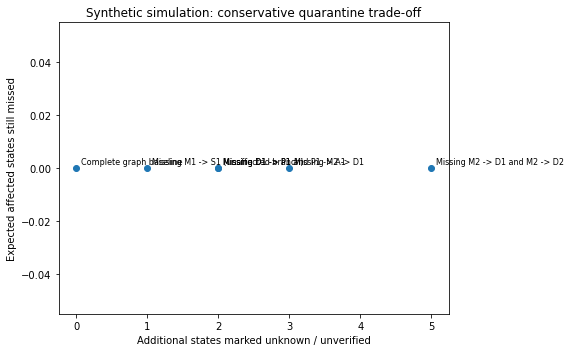

In [8]:
x = results_df["additional_unknown_count"]
y = results_df["conservative_false_negatives"]

plt.figure(figsize=(8, 5))
plt.scatter(x, y)
for _, row in results_df.iterrows():
    plt.annotate(row["scenario"], (row["additional_unknown_count"], row["conservative_false_negatives"]),
                 xytext=(5, 4), textcoords="offset points", fontsize=8)
plt.xlabel("Additional states marked unknown / unverified")
plt.ylabel("Expected affected states still missed")
plt.title("Synthetic simulation: conservative quarantine trade-off")
plt.tight_layout()
plt.show()

## 8. Assertions and consistency checks

These assertions test the declared synthetic policy and metric calculations. They do not establish that this policy is effective in real systems.

In [9]:
# Complete graph baseline: no missing edges, so no uncertainty expansion.
complete = results_df.loc[results_df["scenario"] == "Complete graph baseline"].iloc[0]
assert complete["baseline_false_negatives"] == 0
assert complete["conservative_false_negatives"] == 0
assert complete["additional_unknown_count"] == 0

# Missing D1 -> P1: baseline misses P1 and A1; conservative policy's boundary includes them.
missing_d1_p1 = results_df.loc[results_df["scenario"] == "Missing D1 -> P1"].iloc[0]
assert missing_d1_p1["baseline_false_negatives"] == 2
assert missing_d1_p1["conservative_false_negatives"] == 0
assert missing_d1_p1["conservative_coverage"] == 1.0

# Missing M2 -> D1: conservative uncertainty boundary includes D1's descendants.
missing_m2_d1 = results_df.loc[results_df["scenario"] == "Missing M2 -> D1"].iloc[0]
assert missing_m2_d1["baseline_false_negatives"] == 3
assert missing_m2_d1["conservative_false_negatives"] == 0

# Unaffected branch edge removal should not create poison-source descendants.
unaffected = results_df.loc[results_df["scenario"] == "Missing M1 -> S1 (unaffected branch)"].iloc[0]
assert unaffected["baseline_false_negatives"] == 0
assert unaffected["conservative_false_negatives"] == 0

# Metrics stay within valid bounds.
for col in ["baseline_fnr", "conservative_fnr", "baseline_coverage", "conservative_coverage"]:
    assert results_df[col].between(0, 1).all()

print("PASS: complete-graph baseline has no false negatives or extra unknown states.")
print("PASS: missing D1 -> P1 case is covered by the declared conservative uncertainty boundary.")
print("PASS: missing M2 -> D1 case is covered by the declared conservative uncertainty boundary.")
print("PASS: unaffected-branch edge removal does not create descendant false negatives.")
print("PASS: rate metrics remain between 0 and 1.")
print("All Lab 01.3 assertions passed.")

PASS: complete-graph baseline has no false negatives or extra unknown states.
PASS: missing D1 -> P1 case is covered by the declared conservative uncertainty boundary.
PASS: missing M2 -> D1 case is covered by the declared conservative uncertainty boundary.
PASS: unaffected-branch edge removal does not create descendant false negatives.
PASS: rate metrics remain between 0 and 1.
All Lab 01.3 assertions passed.


## 9. Export CSV artifacts

In [10]:
results_df.to_csv("trustsr_lab01_3_policy_comparison.csv", index=False)
state_tables.to_csv("trustsr_lab01_3_state_classifications.csv", index=False)

print("Generated files:")
print("- trustsr_lab01_3_policy_comparison.csv")
print("- trustsr_lab01_3_state_classifications.csv")

Generated files:
- trustsr_lab01_3_policy_comparison.csv
- trustsr_lab01_3_state_classifications.csv


## 10. Interpretation and limitations

### What this simulation can show

It can show how the two precisely defined policies behave on the chosen synthetic graph when a missing-edge signal is supplied.

### Critical caveat about this conservative policy

The uncertainty boundary in this notebook uses the fixed ground-truth graph to find descendants of the dependent endpoint of each missing edge. This is intentionally a controlled simulation convenience. In a real deployment, ground truth is not known to the policy; the system would need an independently maintained state inventory, event provenance, or conservative boundary rule that does not rely on hidden ground-truth edges.

Therefore, the conservative policy's reduced false-negative count here must **not** be reported as evidence that it will improve real-world detection. It may increase unnecessary quarantine, and its behavior depends on the reliability of the missing-edge signal and boundary construction.

### Not established by this lab

- Real-world detection or recovery effectiveness.
- Realistic false-negative rates.
- Formal soundness or completeness guarantees.
- A validated operational quarantine policy.
- Support for any unverified numerical claims in the TRUSTSR monograph.

### Research reporting rule

Call these outputs **synthetic simulation results**. State the policy assumptions next to any table or figure that uses them. The next research step should replace the ground-truth-dependent boundary with a deployable uncertainty rule and evaluate both missed contamination and over-quarantine on defensible traces.